[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch45_LabCh45_Tiny_ViT.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 45: Vision Transformers** (Part X: Seeing More).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=45](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=45)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch45 - A tiny Vision Transformer
## Cut a picture into squares, call each square a word, and race the result against a small CNN

This lab goes with **Chapter 45** of *The Why Book of Deep Learning, Part 2*.

A Vision Transformer (ViT, 2020) is the encoder block of Chapter 23 with one new part in front of it: a step
that cuts the image into small squares and turns each square into a vector. In this lab you build that step
by hand, prove that it is a convolution you already know, count every parameter of a small ViT before Keras
does, and then train it five times beside a small CNN to see what each one is told for free and what each
one has to learn.

| TinyViT | value |
|---|---|
| image | 32 × 32 × 3 (CIFAR-10) |
| patch | 4 × 4, so 8 × 8 = 64 patches |
| width d | 64 |
| heads | 4 (each 16 wide) |
| blocks | 2, pre-norm, no mask |
| feed-forward width | 256 |
| positions | a learnt table, one row per patch |
| readout | the mean of the 64 token vectors, then `Dense(10)` |

The block is the block of TinyGPT (Chapter 35) with its causal mask removed. Nothing else in it changes.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Cut an image into patches and say how many tokens any image and patch size give | Step 3 |
| Show that the patch projection is a convolution with kernel P and stride P | Step 4 |
| Count a ViT's parameters by hand and check the count against Keras | Steps 5 and 6 |
| Follow the shapes from `(batch, 32, 32, 3)` to `(batch, 10)` | Step 7 |
| Compare a ViT and a CNN fairly: same data, same steps, same augmentation | Steps 8 to 12 |
| Show what a ViT without positions cannot see | Steps 13 and 14 |
| Read a position-similarity map and an attention map, and say what they do not prove | Steps 15 and 16 |
| Work out what a smaller patch costs | Step 17 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** four to five minutes on a laptop CPU, nearly all of it in Steps 10, 11 and 13 (five
> training runs). No GPU is needed. The only download is CIFAR-10 from `keras.datasets`.

> **Honest scale:** this is a miniature. The models have about a hundred thousand parameters, they see
> 10,000 images (a fifth of CIFAR-10) and they train for 600 steps. Every accuracy printed here is low, for
> the ViT and for the CNN. They are numbers for comparing five runs with each other, and for nothing else.
> Part 1's Chapter 16 CNN reached 77.51% on this data set with 1,341,226 parameters, 45,000 of the 50,000 images and 15
> epochs; well-tuned models of either family pass 95%.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 45
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=2, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The data: CIFAR-10, a fifth of it, and a tenth of that

CIFAR-10 is the data set of Chapter 16: 50,000 training and 10,000 test photographs of 32 × 32 pixels in ten
classes. To keep five training runs inside five minutes we take **10,000 training images** at random and call
that set "all labels" for this lab. The first 1,000 of them are the "one tenth" set. The test set is the full
10,000 test images, and no model ever trains on it.

Pixels are divided by 255 and nothing else is done to them.

> **Predict:** a random 1,000 images from ten equally common classes. Will every class have exactly 100?

In [2]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()

N_ALL, N_TENTH = 10_000, 1_000
pick = np.random.default_rng(0).permutation(len(x_train_full))[:N_ALL]
x_all, y_all = x_train_full[pick], y_train_full[pick]
x_tenth, y_tenth = x_all[:N_TENTH], y_all[:N_TENTH]

print("all labels :", x_all.shape, " per class:", np.bincount(y_all))
print("one tenth  :", x_tenth.shape, "  per class:", np.bincount(y_tenth))
print("test       :", x_test.shape)
print("pixel range:", x_all.min(), "to", x_all.max())

all labels : (10000, 32, 32, 3)  per class: [1029  998 1024  975 1030  968  977  992 1017  990]
one tenth  : (1000, 32, 32, 3)   per class: [102 103 107  98 105 102  98  99  95  91]
test       : (10000, 32, 32, 3)
pixel range: 0.0 to 1.0


---
## Step 3 - Patchify by hand

A transformer takes a sequence of vectors. An image is a grid of pixels. The bridge is to cut the image into
P × P squares and flatten each square into one long vector.

An H × W × C image cut into P × P patches gives (H / P) · (W / P) patches of P · P · C numbers each.

> **Predict:** for our 32 × 32 × 3 image and P = 4: how many patches, and how many numbers in each? Then the
> same for P = 8 and P = 2. And what happens with P = 5?

P = 8:   16 patches of 192 numbers   shape (1, 16, 192)
P = 4:   64 patches of  48 numbers   shape (1, 64, 48)
P = 2:  256 patches of  12 numbers   shape (1, 256, 12)
patch 0 is the top-left 4 x 4 square: True
patch 9 is row 1, column 1 of the grid: True
P = 5: patch size 5 does not divide a 32 x 32 image


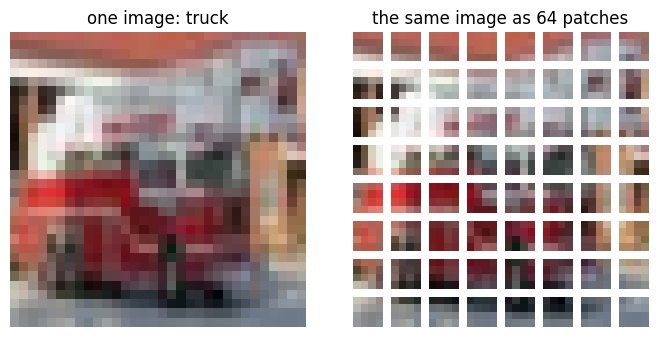

In [3]:
def patchify(images, p):
    """images (n, H, W, C) -> patches (n, (H/p)*(W/p), p*p*C), read left to right, top to bottom."""
    n, h, w, c = images.shape
    assert h % p == 0 and w % p == 0, f"patch size {p} does not divide a {h} x {w} image"
    x = images.reshape(n, h // p, p, w // p, p, c)      # split both axes into (blocks, within-block)
    x = x.transpose(0, 1, 3, 2, 4, 5)                   # (n, rows, cols, p, p, c)
    return x.reshape(n, (h // p) * (w // p), p * p * c)


for p in (8, 4, 2):
    patches = patchify(x_all[:1], p)
    print(f"P = {p}: {patches.shape[1]:4d} patches of {patches.shape[2]:3d} numbers   shape {patches.shape}")

one = patchify(x_all[:1], 4)[0]
print("patch 0 is the top-left 4 x 4 square:", bool(np.allclose(one[0], x_all[0, :4, :4, :].ravel())))
print("patch 9 is row 1, column 1 of the grid:", bool(np.allclose(one[9], x_all[0, 4:8, 4:8, :].ravel())))
try:
    patchify(x_all[:1], 5)
except AssertionError as e:
    print("P = 5:", e)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(x_all[0]); axes[0].set_title(f"one image: {CLASSES[y_all[0]]}"); axes[0].axis("off")
grid = one.reshape(8, 8, 4, 4, 3)
canvas = np.ones((8 * 5 - 1, 8 * 5 - 1, 3), dtype="float32")
for r in range(8):
    for c in range(8):
        canvas[r * 5:r * 5 + 4, c * 5:c * 5 + 4] = grid[r, c]
axes[1].imshow(canvas); axes[1].set_title("the same image as 64 patches"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### Why we see this

With P = 4 the image becomes a "sentence" of 64 "words", each 48 numbers long. Halve the patch and the
sentence is four times longer; double it and the sentence is four times shorter. Nothing was learnt yet and
nothing was lost: put the 64 patches back in their places and you have the image again.

The patch size must divide the image. With P = 5 there is no way to tile 32 pixels, and a careful
implementation says so instead of quietly dropping the last two columns.

---
## Step 4 - The projection is a convolution with kernel P and stride P

Each 48-number patch is multiplied by one shared matrix of 48 × d weights (plus d biases) to give a
d-number vector. That is a `Dense(d)` applied to every patch.

Now recall Chapter 13: a convolution slides a brick of weights over the image and takes a dot product at
every stop. Give the brick the size of a patch (4 × 4 × 3) and make it step 4 pixels at a time, so that its
stops do not overlap. Each stop is then one patch, and each of the d filters is one row of the matrix.

> **Predict:** how many parameters has `Conv2D(64, kernel_size=4, strides=4)` on a 3-channel image? And will
> its output equal patchify-then-multiply to the last decimal?

In [4]:
P, D = 4, 64
conv = layers.Conv2D(D, kernel_size=P, strides=P, name="patch_projection")
out_conv = conv(x_all[:8]).numpy()                              # (8, 8, 8, 64)
kernel, bias = [w.numpy() for w in conv.weights]                # (4, 4, 3, 64) and (64,)
print("conv output:", out_conv.shape, "| kernel:", kernel.shape, "| parameters:", conv.count_params())
assert conv.count_params() == P * P * 3 * D + D == 3_136

matrix = kernel.reshape(P * P * 3, D)                           # the same weights as a 48 x 64 matrix
out_hand = patchify(x_all[:8], P) @ matrix + bias               # (8, 64, 64)
diff = np.abs(out_hand - out_conv.reshape(8, 64, D)).max()
print("patchify, then one matrix:", out_hand.shape)
print(f"largest difference between the two: {diff:.2e}")
assert diff < 1e-5

conv output: (8, 8, 8, 64) | kernel: (4, 4, 3, 64) | parameters: 3136
patchify, then one matrix: (8, 64, 64)
largest difference between the two: 1.23e-07


### Why we see this

The two routes agree to rounding. "Cut into patches, flatten, apply a dense layer" and "a convolution with
kernel 4 and stride 4" are the same arithmetic, so every ViT implementation uses the convolution: it is one
layer and it is fast.

The count is the Chapter 14 formula: (4 · 4 · 3) weights per filter, 64 filters, 64 biases: 3,136. For
ViT-Base/16 the same formula gives 16 · 16 · 3 · 768 + 768 = 590,592 (Step 18).

This is the **only** place where a ViT uses the fact that pixels sit next to each other. After it, the model
holds 64 vectors and no idea where any of them came from.

---
## Step 5 - Count the ViT before building it

* **patch projection:** P · P · 3 · d + d
* **position table:** one row of d numbers per token
* **one block:** attention 4d² + 4d, feed-forward (d · ff + ff) + (ff · d + d), two LayerNorms of 2d each.
  This is exactly the TinyGPT block of Chapter 35.
* **final LayerNorm:** 2d
* **head:** d · 10 + 10
* a **class token**, if used, adds d numbers and one more row in the position table

> **Predict:** which part is the biggest? And how many parameters does the class token cost in all?

In [5]:
def count_vit(image=32, patch=4, channels=3, d=64, blocks=2, ff=256, classes=10, positions=True, class_token=False):
    """The hand count of a ViT. The number of heads does not appear: splitting d into heads moves no weights."""
    n_tokens = (image // patch) ** 2 + (1 if class_token else 0)
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    one_block = attention + feed_forward + 2 * (2 * d)
    parts = {"patch projection": patch * patch * channels * d + d,
             "class token": d if class_token else 0,
             "position table": n_tokens * d if positions else 0,
             "blocks": blocks * one_block,
             "final norm": 2 * d,
             "head": d * classes + classes}
    return parts, one_block


vit_parts, vit_block = count_vit()
print(f"one block: {vit_block:,}  (the TinyGPT block of Chapter 35)")
for name, n in vit_parts.items():
    print(f"  {name:17s} {n:>8,}   {n / sum(vit_parts.values()):6.1%}")
VIT_HAND = sum(vit_parts.values())
print(f"  {'TOTAL':17s} {VIT_HAND:>8,}")
print("with a class token instead of the mean:", f"{sum(count_vit(class_token=True)[0].values()):,}")
print("without the position table            :", f"{sum(count_vit(positions=False)[0].values()):,}")

one block: 49,984  (the TinyGPT block of Chapter 35)
  patch projection     3,136     2.9%
  class token              0     0.0%
  position table       4,096     3.8%
  blocks              99,968    92.6%
  final norm             128     0.1%
  head                   650     0.6%
  TOTAL              107,978
with a class token instead of the mean: 108,106
without the position table            : 103,882


---
## Step 6 - Build TinyViT

`build_vit()` is the whole model:

1. a random left-right flip (training only; the CNN gets the same one)
2. the patch projection of Step 4, then a reshape from an 8 × 8 grid to a row of 64 tokens
3. add the learnt position table (one row per token)
4. twice: LayerNorm → self-attention → add back; LayerNorm → Dense(256, gelu) → Dense(64) → add back
5. a final LayerNorm, the mean over the 64 tokens, and `Dense(10)`

Compare step 4 with `build_tinygpt` in Chapter 35: the only difference is that `use_causal_mask` is gone.
In a picture there is no future to hide, so every patch may look at every other patch.

`pool="cls"` swaps the mean for a **class token**: one extra learnt vector placed in front of the 64 patch
tokens, whose output is the only one the head reads. That is what the original ViT did.

> **Predict:** will Keras agree with the three hand counts of Step 5?

In [6]:
class ClassToken(layers.Layer):
    """tokens (batch, N, d) -> (batch, N + 1, d): one learnt vector put in front of every sequence."""

    def __init__(self, d, **kwargs):
        super().__init__(**kwargs)
        self.token = self.add_weight(shape=(1, 1, d), initializer="zeros", name="class_token")

    def call(self, x):
        batch = keras.ops.shape(x)[0]
        return keras.ops.concatenate([keras.ops.broadcast_to(self.token, (batch, 1, x.shape[-1])), x], axis=1)


class PatchPositions(layers.Layer):
    """tokens (batch, N, d) -> the same plus a learnt table of N rows: one position vector per token."""

    def __init__(self, n_tokens, d, **kwargs):
        super().__init__(**kwargs)
        self.table = self.add_weight(shape=(n_tokens, d), name="position_table",
                                     initializer=keras.initializers.RandomNormal(stddev=0.02))

    def call(self, x):
        return x + self.table


def build_vit(image=32, patch=4, d=64, heads=4, blocks=2, ff=256, classes=10, positions=True, pool="mean"):
    """TinyViT: images (batch, image, image, 3) -> logits (batch, classes). Pre-norm blocks, full attention."""
    assert image % patch == 0, "the patch size must divide the image size"
    n = (image // patch) ** 2
    images = layers.Input(shape=(image, image, 3), name="image")
    x = layers.RandomFlip("horizontal", name="flip")(images)
    x = layers.Conv2D(d, kernel_size=patch, strides=patch, name="patch_projection")(x)
    x = layers.Reshape((n, d), name="grid_to_row")(x)
    if pool == "cls":
        x = ClassToken(d, name="class_token")(x)
        n += 1
    if positions:
        x = PatchPositions(n, d, name="positions")(x)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, name=f"block{b}_attention")(h, h)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    if pool == "cls":
        x = layers.Lambda(lambda t: t[:, 0], name="read_class_token")(x)
    else:
        x = layers.GlobalAveragePooling1D(name="mean_of_tokens")(x)
    logits = layers.Dense(classes, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(images, logits, name="TinyViT")


keras.utils.set_random_seed(SEED)
vit = build_vit()
vit.summary()
print("Keras count:", f"{vit.count_params():,}", "| hand count:", f"{VIT_HAND:,}")
assert vit.count_params() == VIT_HAND == 107_978
assert vit.get_layer("patch_projection").count_params() == 3_136
assert build_vit(pool="cls").count_params() == sum(count_vit(class_token=True)[0].values()) == 108_106
assert build_vit(positions=False).count_params() == sum(count_vit(positions=False)[0].values()) == 103_882
print("class-token version: 108,106 = 107,978 + 64 (the token) + 64 (its row in the position table)")
print("no-position version: 103,882 = 107,978 - 64 x 64")

Model: "TinyViT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flip (RandomFlip)   │ (None, 32, 32, 3) │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_projection    │ (None, 8, 8, 64)  │      3,136 │ flip[0][0]        │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grid_to_row         │ (None, 64, 64)    │          0 │ patch_projection… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positions           │ (None, 64, 64)    │      4,096 │ grid_to_row[0][0] │
│ (PatchPositions)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm1        │ (None, 64, 64)    │        128 │ positions[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attention    │ (None, 64, 64)    │     16,640 │ block1_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block1_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add1 (Add)   │ (None, 64, 64)    │          0 │ positions[0][0],  │
│                     │                   │            │ block1_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm2        │ (None, 64, 64)    │        128 │ block1_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_wide      │ (None, 64, 256)   │     16,640 │ block1_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_narrow    │ (None, 64, 64)    │     16,448 │ block1_ff_wide[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add2 (Add)   │ (None, 64, 64)    │          0 │ block1_add1[0][0… │
│                     │                   │            │ block1_ff_narrow… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm1        │ (None, 64, 64)    │        128 │ block1_add2[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attention    │ (None, 64, 64)    │     16,640 │ block2_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block2_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_add1 (Add)   │ (None, 64, 64)    │          0 │ block1_add2[0][0… │
│                     │                   │            │ block2_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm2        │ (None, 64, 64)    │        128 │ block2_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_ff_wide      │ (None, 64, 256)   │     16,640 │ block2_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 107,978 (421.79 KB)

 Trainable params: 107,978 (421.79 KB)

 Non-trainable params: 0 (0.00 B)

Keras count: 107,978 | hand count: 107,978


class-token version: 108,106 = 107,978 + 64 (the token) + 64 (its row in the position table)
no-position version: 103,882 = 107,978 - 64 x 64


### Why we see this

All three counts match. Look at where the weights are: the two blocks hold 92.6% of the model, the patch
projection 2.9%, the position table 3.8%. Everything that is specific to images, the projection and the
table, is under 7% of the weights. The rest is the block you already knew.

The class token costs 128 numbers. It is not magic: it is one more token whose only job is to collect a
summary, and the mean of the patch tokens is the other common way to get one.

---
## Step 7 - Follow the shapes

> **Predict:** the shape after the patch projection, after the reshape, after each block, after the mean, and
> at the output, for a batch of 4 images. Which layers change the shape?

In [7]:
names = ["patch_projection", "grid_to_row", "positions", "block1_add2", "block2_add2", "mean_of_tokens", "head"]
labels = ["patch projection", "grid to row of tokens", "+ position table", "after block 1", "after block 2",
          "mean of the tokens", "head (logits)"]
probe = keras.Model(vit.input, [vit.get_layer(n).output for n in names])
print(f"{'image':24s} {str(x_all[:4].shape)}")
for label, out in zip(labels, probe(x_all[:4])):
    print(f"{label:24s} {tuple(out.shape)}")

image                    (4, 32, 32, 3)


patch projection         (4, 8, 8, 64)
grid to row of tokens    (4, 64, 64)
+ position table         (4, 64, 64)
after block 1            (4, 64, 64)
after block 2            (4, 64, 64)
mean of the tokens       (4, 64)
head (logits)            (4, 10)


---
## Step 8 - The opponent: a small CNN of similar size

Three 3 × 3 convolutions with 32, 64 and 128 filters, a 2 × 2 max-pool after the first two, global average
pooling and `Dense(10)`. It is the conv-pool pattern of Chapter 16 cut down to the size of TinyViT, with the
same random flip in front.

Count it with the Chapter 14 formula: (3 · 3 · channels in + 1) · filters.

> **Predict:** the three convolution counts and the total. Is it larger or smaller than TinyViT's 107,978?

In [8]:
def build_cnn(classes=10):
    """A small CNN: images (batch, 32, 32, 3) -> logits (batch, classes)."""
    images = layers.Input(shape=(32, 32, 3), name="image")
    x = layers.RandomFlip("horizontal", name="flip")(images)
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1")(x)
    x = layers.MaxPooling2D(name="pool1")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2")(x)
    x = layers.MaxPooling2D(name="pool2")(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3")(x)
    x = layers.GlobalAveragePooling2D(name="mean_of_cells")(x)
    logits = layers.Dense(classes, name="head")(x)
    return keras.Model(images, logits, name="TinyCNN")


cnn_parts = {"conv1": (3 * 3 * 3 + 1) * 32, "conv2": (3 * 3 * 32 + 1) * 64, "conv3": (3 * 3 * 64 + 1) * 128,
             "head": 128 * 10 + 10}
CNN_HAND = sum(cnn_parts.values())
keras.utils.set_random_seed(SEED + 1)
cnn = build_cnn()
cnn.summary()
print(cnn_parts)
print("Keras count:", f"{cnn.count_params():,}", "| hand count:", f"{CNN_HAND:,}")
assert cnn.count_params() == CNN_HAND == 94_538
print(f"TinyCNN is {CNN_HAND / VIT_HAND:.0%} of TinyViT's size")

Model: "TinyCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flip (RandomFlip)               │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mean_of_cells                   │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,538 (369.29 KB)

 Trainable params: 94,538 (369.29 KB)

 Non-trainable params: 0 (0.00 B)

{'conv1': 896, 'conv2': 18496, 'conv3': 73856, 'head': 1290}
Keras count: 94,538 | hand count: 94,538
TinyCNN is 88% of TinyViT's size


### Why we see this

The CNN is a little smaller than the ViT (94,538 against 107,978), so if it wins it will not be because it
had more weights.

What matters is what each design **assumes**. The CNN's first layer looks at 3 × 3 neighbourhoods and uses
the same 896 weights at every one of the 1,024 pixel positions. Two assumptions are built into that sentence:
nearby pixels belong together (**locality**), and a pattern means the same thing wherever it appears
(**translation equivariance**, Chapter 13). Nobody has to teach it either.

The ViT assumes them once, weakly, inside each 4 × 4 patch. Between patches it assumes nothing: patch 0 may
attend to patch 63 as easily as to patch 1, and whether neighbours matter more is something the position
table and the attention weights must learn from examples.

---
## Step 9 - The loss before training

Ten classes, no knowledge: an untrained classifier should give each class about one tenth and pay about
ln 10.

> **Predict:** ln 10 to two decimals, and the accuracy of an untrained model.

In [9]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
for name, m in [("TinyViT", vit), ("TinyCNN", cnn)]:
    m.compile(loss=loss_fn, metrics=["accuracy"])
    loss, acc = m.evaluate(x_test, y_test, batch_size=500, verbose=0)
    print(f"{name}: loss before training {loss:.3f} (ln 10 = {np.log(10):.3f})   accuracy {acc:.1%}")

TinyViT: loss before training 2.314 (ln 10 = 2.303)   accuracy 10.9%


TinyCNN: loss before training 2.304 (ln 10 = 2.303)   accuracy 10.0%


---
## Step 10 - Train both on all 10,000 labels

A fair race needs the same conditions for both runners:

* the same images, in batches of 100
* the same number of weight updates: **600 steps** (6 passes over the 10,000 images)
* the same augmentation: a random left-right flip, and nothing else
* the same optimiser and schedule: AdamW with weight decay 0.05, 50 steps of warm-up, then a cosine down,
  gradients clipped at norm 1 (the transformer recipe of Chapters 8 and 35)

One thing is allowed to differ: the peak learning rate, because each design has its own. We tried three
values for each model and scored them on 2,000 held-out **training** images, not on the test set:

| peak learning rate | 0.0005 | 0.001 | 0.002 | 0.005 | 0.01 | 0.02 |
|---|---|---|---|---|---|---|
| ViT, held-out accuracy | 41.9% | **46.3%** | 44.8% | | | |
| CNN, held-out accuracy | | | | 50.8% | **52.5%** | 48.5% |

So the ViT runs at 0.001 and the CNN at 0.01. Trial 5 lets you check what happens if you swap them.

> **Predict:** which model will have the higher test accuracy after 600 steps? By how much? And will either
> be anywhere near the 77.51% of the Chapter 16 network?

> This cell takes about a minute.

In [10]:
BATCH, STEPS = 100, 600
PEAK_LR = {"vit": 1e-3, "cnn": 1e-2}
results = {}


def train(model, x, y, peak_lr, steps=STEPS, batch=BATCH):
    """Train for a fixed number of steps, however many images there are. Returns a dict of what happened."""
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=peak_lr, warmup_steps=50, decay_steps=steps - 50, alpha=0.02)
    model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.05, clipnorm=1.0),
                  loss=loss_fn, metrics=["accuracy"])
    epochs = steps * batch // len(x)
    t0 = time.time()
    hist = model.fit(x, y, batch_size=batch, epochs=epochs, verbose=0)
    seconds = time.time() - t0
    train_loss, train_acc = model.evaluate(x, y, batch_size=500, verbose=0)       # flip is off here
    test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=500, verbose=0)
    return {"epochs": epochs, "seconds": seconds, "train_acc": train_acc, "test_acc": test_acc,
            "train_loss": train_loss, "test_loss": test_loss, "curve": hist.history["accuracy"]}


def report(key):
    r = results[key]
    print(f"{key:22s} {r['epochs']:3d} epochs {r['seconds']:4.0f} s   train {r['train_acc']:6.1%}   "
          f"test {r['test_acc']:6.1%}   gap {r['train_acc'] - r['test_acc']:+6.1%}")


results["ViT, all labels"] = train(vit, x_all, y_all, PEAK_LR["vit"])
report("ViT, all labels")
results["CNN, all labels"] = train(cnn, x_all, y_all, PEAK_LR["cnn"])
report("CNN, all labels")

ViT, all labels          6 epochs   56 s   train  44.4%   test  42.8%   gap  +1.5%


CNN, all labels          6 epochs   18 s   train  52.5%   test  51.3%   gap  +1.1%


### Why we see this

Both numbers are low, and they should be: a hundred thousand weights, a fifth of the data, six passes.
Neither model has finished learning (look at how small the gap between training and test accuracy is). Do
not read either number as "what a CNN gets" or "what a ViT gets" on CIFAR-10.

Read the **difference**. With 10,000 labelled images the small CNN is ahead of the small ViT by several
points. That is more than noise: the test set has 10,000 images, so each accuracy carries about half a point
of sampling error, and a different seed moves a run by a point or two.

Now take nine tenths of the labels away.

---
## Step 11 - The same race with one tenth of the labels

Fresh copies of both models, the first 1,000 of the 10,000 images, and the **same 600 steps**. Each image is
now seen 60 times instead of 6, so neither model can complain about too few updates.

> **Predict:** which model loses more when the labels are cut to a tenth? What will the ViT's *training*
> accuracy be after seeing each of 1,000 images 60 times?

In [11]:
keras.utils.set_random_seed(SEED + 2)
vit_tenth = build_vit()
results["ViT, one tenth"] = train(vit_tenth, x_tenth, y_tenth, PEAK_LR["vit"])
report("ViT, one tenth")
keras.utils.set_random_seed(SEED + 3)
cnn_tenth = build_cnn()
results["CNN, one tenth"] = train(cnn_tenth, x_tenth, y_tenth, PEAK_LR["cnn"])
report("CNN, one tenth")

ViT, one tenth          60 epochs   57 s   train  89.8%   test  34.2%   gap +55.6%


CNN, one tenth          60 epochs   17 s   train  79.5%   test  48.0%   gap +31.5%


---
## Step 12 - The four runs side by side

             all 10,000      1,000     lost
ViT               42.8%      34.2%     8.6%
CNN               51.3%      48.0%     3.4%
CNN minus ViT: +8.5% with all labels, +13.7% with one tenth
training accuracy with one tenth: ViT 89.8%, CNN 79.5%


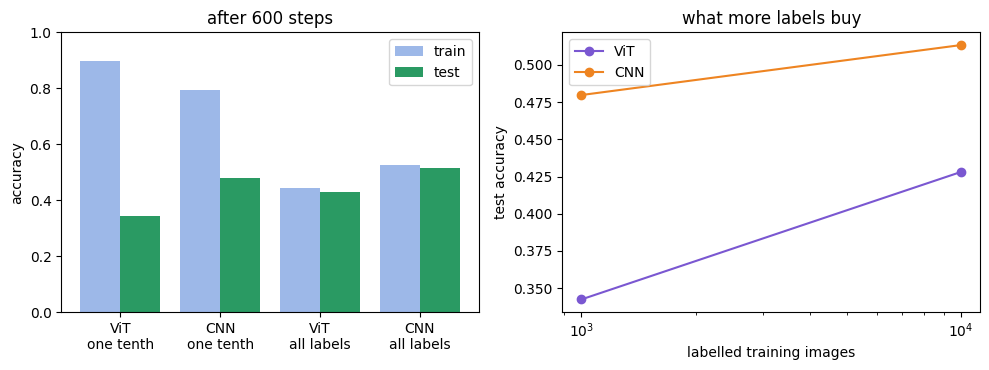

In [12]:
print(f"{'':10s} {'all 10,000':>12s} {'1,000':>10s} {'lost':>8s}")
for kind in ("ViT", "CNN"):
    a, b = results[f"{kind}, all labels"]["test_acc"], results[f"{kind}, one tenth"]["test_acc"]
    print(f"{kind:10s} {a:12.1%} {b:10.1%} {a - b:8.1%}")
gap_all = results["CNN, all labels"]["test_acc"] - results["ViT, all labels"]["test_acc"]
gap_tenth = results["CNN, one tenth"]["test_acc"] - results["ViT, one tenth"]["test_acc"]
print(f"CNN minus ViT: {gap_all:+.1%} with all labels, {gap_tenth:+.1%} with one tenth")
print("training accuracy with one tenth:",
      f"ViT {results['ViT, one tenth']['train_acc']:.1%}, CNN {results['CNN, one tenth']['train_acc']:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
keys = ["ViT, one tenth", "CNN, one tenth", "ViT, all labels", "CNN, all labels"]
xs = np.arange(4)
axes[0].bar(xs - 0.2, [results[k]["train_acc"] for k in keys], 0.4, label="train", color="#9db8e8")
axes[0].bar(xs + 0.2, [results[k]["test_acc"] for k in keys], 0.4, label="test", color="#2a9a63")
axes[0].set_xticks(xs); axes[0].set_xticklabels([k.replace(", ", "\n") for k in keys])
axes[0].set_ylabel("accuracy"); axes[0].set_ylim(0, 1); axes[0].legend(); axes[0].set_title(f"after {STEPS} steps")
for kind, color in (("ViT", "#7a57d1"), ("CNN", "#ee8421")):
    axes[1].plot([1000, 10000], [results[f"{kind}, one tenth"]["test_acc"], results[f"{kind}, all labels"]["test_acc"]],
                 "o-", color=color, label=kind)
axes[1].set_xscale("log"); axes[1].set_xlabel("labelled training images"); axes[1].set_ylabel("test accuracy")
axes[1].set_title("what more labels buy"); axes[1].legend()
plt.tight_layout(); plt.show()

### Why we see this

The CNN wins at both sizes, and the gap is much wider with 1,000 labels than with 10,000. Cutting the labels
to a tenth cost the ViT more than twice as many points as it cost the CNN. Said the other way round: ten
times more labels helped the ViT more than twice as much.

Look at the training accuracies with one tenth. The ViT can recite about nine in ten of its 1,000 training
images and still gets only about a third of the test images right: it found a way to tell those 1,000
pictures apart that has little to do with what is in them. The CNN memorises too (its gap is large as well),
but what it learns on the way carries over to new pictures far better, because its weights are forced to be
the same small filters at every position, and filters that work everywhere tend to be filters that mean
something.

This is **inductive bias** in miniature. The CNN was told that neighbours matter and that position does not;
the ViT had to work both out from examples, and 1,000 examples are not enough to do it. The well-established
pattern at full size is the same shape with bigger numbers: trained from scratch on a small or medium data
set a CNN wins; pretrained on hundreds of millions of images a ViT matches or passes it.

What this lab does **not** show is the ViT catching up. For that, the data, the model and the training time
would all have to grow by orders of magnitude, with far heavier augmentation. All you can see here is the
direction: the ViT's disadvantage shrinks as the labels grow.

---
## Step 13 - Remove the position table

`build_vit(positions=False)` drops the 4,096 numbers of the position table. Everything else is identical.
Chapter 34 showed that attention treats its input as a bag: without positions the model receives 64 patch
vectors and no information about where each one was.

> **Predict:** how many points of test accuracy will that cost on all 10,000 labels: none, a few, or most of
> them? (Think about what a classifier could do with a bag of 4 × 4 patches.)

> This cell takes about a minute.

In [13]:
keras.utils.set_random_seed(SEED + 4)
vit_nopos = build_vit(positions=False)
results["ViT, no positions"] = train(vit_nopos, x_all, y_all, PEAK_LR["vit"])
report("ViT, all labels")
report("ViT, no positions")
lost = results["ViT, all labels"]["test_acc"] - results["ViT, no positions"]["test_acc"]
print(f"the position table (4,096 numbers, 3.8% of the model) was worth {lost:+.1%} of test accuracy")

ViT, all labels          6 epochs   56 s   train  44.4%   test  42.8%   gap  +1.5%
ViT, no positions        6 epochs   55 s   train  38.2%   test  37.0%   gap  +1.2%
the position table (4,096 numbers, 3.8% of the model) was worth +5.9% of test accuracy


---
## Step 14 - The jigsaw test

Accuracy is a blunt way to see what the positions do. Here is a sharper one. Cut every test image into its 64
patches and put them back in a **scrambled order** (the same scramble for every image). To a person the
result is confetti.

> **Predict:** the test accuracy on scrambled images for (a) the ViT without positions, (b) the ViT with
> positions, (c) the CNN.

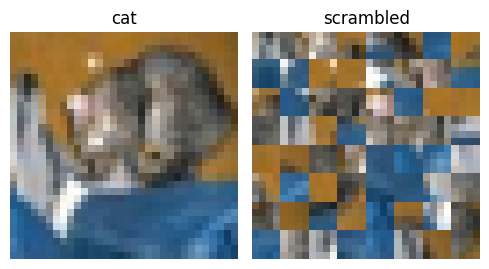

ViT, no positions    whole images  37.0%   scrambled  37.0%


ViT, with positions  whole images  42.8%   scrambled  32.4%


CNN                  whole images  51.3%   scrambled  24.9%


ViT without positions gives the same answer for an image and its scramble 100.0% of the time


In [14]:
def scramble(images, p=4, seed=0):
    """Cut each image into p x p patches and put them back in one fixed random order."""
    n, h, w, c = images.shape
    g = h // p
    order = np.random.default_rng(seed).permutation(g * g)
    patches = patchify(images, p)[:, order]                              # (n, 64, 48), shuffled
    return patches.reshape(n, g, g, p, p, c).transpose(0, 1, 3, 2, 4, 5).reshape(n, h, w, c)


x_scrambled = scramble(x_test)
fig, axes = plt.subplots(1, 2, figsize=(5, 2.7))
axes[0].imshow(x_test[0]); axes[0].set_title(CLASSES[y_test[0]]); axes[0].axis("off")
axes[1].imshow(x_scrambled[0]); axes[1].set_title("scrambled"); axes[1].axis("off")
plt.tight_layout(); plt.show()

jigsaw = {}
for name, m in [("ViT, no positions", vit_nopos), ("ViT, with positions", vit), ("CNN", cnn)]:
    whole = m.evaluate(x_test, y_test, batch_size=500, verbose=0)[1]
    mixed = m.evaluate(x_scrambled, y_test, batch_size=500, verbose=0)[1]
    jigsaw[name] = (whole, mixed)
    print(f"{name:20s} whole images {whole:6.1%}   scrambled {mixed:6.1%}")
same = (vit_nopos.predict(x_test[:2000], batch_size=500, verbose=0).argmax(1) ==
        vit_nopos.predict(x_scrambled[:2000], batch_size=500, verbose=0).argmax(1)).mean()
print(f"ViT without positions gives the same answer for an image and its scramble {same:.1%} of the time")

### Why we see this

The ViT without positions gives the same answers for a photograph and for its confetti. It is not being
robust. It **cannot tell them apart**: attention sees a bag, the mean over tokens is a bag operation, and so
the whole model is a function of *which patches are present*, never of where they are.

The ViT with positions and the CNN both lose a large part of their accuracy on the scrambled images, which
is the right reaction: they had learnt to use the arrangement, and the arrangement is gone. The CNN, which
leans on arrangement most, falls furthest.

Now the uncomfortable part. On whole images the no-position model was only about six points behind in Step 13. A
bag of small patches is enough to guess CIFAR-10 classes surprisingly often: blue patches suggest sky or sea,
green ones suggest deer, frogs or horses. A model this small, trained this briefly, has barely begun to use
arrangement at all. So a missing position table raises no error and may cost only a few points on an easy
benchmark, while the model stays blind to everything that depends on layout. The jigsaw test is how you catch
it.

---
## Step 15 - What the position table learnt

The table started as 64 rows of small random numbers, with nothing in them about a grid. Take the row of one
patch, measure its cosine similarity (Chapter 18) with all 64 rows, and lay the 64 numbers out as an 8 × 8
map.

> **Predict:** if training taught the table anything about the layout of the image, what should the map for
> the patch at row 3, column 3 look like? And what did it look like before training?

cosine similarity of the patch at (row 0, column 0) with every patch, after training:
[[ 1.    0.72  0.52  0.47  0.65  0.67  0.49  0.46]
 [ 0.41  0.57  0.39  0.63  0.65  0.55  0.53  0.57]
 [ 0.32  0.43  0.45  0.21  0.32  0.34  0.27  0.39]
 [ 0.21  0.18 -0.09 -0.04  0.07 -0.03  0.14  0.01]
 [ 0.02  0.09 -0.09 -0.16 -0.01 -0.12  0.04  0.18]
 [-0.   -0.09 -0.26  0.04  0.08 -0.26 -0.29  0.19]
 [ 0.08 -0.08 -0.17 -0.16 -0.03 -0.25 -0.04  0.4 ]
 [ 0.17 -0.11 -0.12 -0.26 -0.4  -0.16 -0.13  0.2 ]]

cosine similarity of the patch at (row 3, column 3) with every patch, after training:
[[-0.04 -0.19  0.22  0.13  0.05 -0.05  0.34  0.31]
 [ 0.17 -0.05  0.29  0.22 -0.03  0.4   0.2  -0.18]
 [-0.35  0.16  0.51  0.59  0.44  0.37  0.09 -0.48]
 [-0.5   0.44  0.72  1.    0.49  0.18 -0.23 -0.56]
 [-0.62 -0.23  0.57  0.6   0.28  0.4  -0.22 -0.58]
 [-0.58 -0.31 -0.14 -0.4  -0.27 -0.02  0.16 -0.37]
 [-0.29 -0.45 -0.16 -0.06 -0.12  0.1  -0.08 -0.08]
 [-0.38 -0.01 -0.23 -0.14  0.19  0.15  0.17 -0.37]]

mean sim

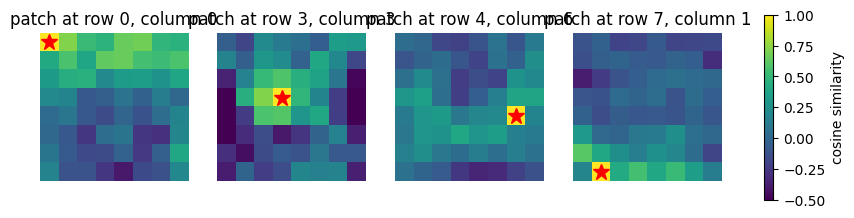

In [15]:
def position_similarity(model):
    table = model.get_layer("positions").table.numpy()                   # (64, 64): 64 patches, 64 numbers each
    unit = table / np.linalg.norm(table, axis=1, keepdims=True)
    return unit @ unit.T                                                 # (64, 64) cosine similarities


sim = position_similarity(vit)
keras.utils.set_random_seed(SEED)
sim_before = position_similarity(build_vit())
rows, cols = np.divmod(np.arange(64), 8)
dist = np.maximum(np.abs(rows[:, None] - rows[None, :]), np.abs(cols[:, None] - cols[None, :]))   # in patches

for r, c in [(0, 0), (3, 3)]:
    print(f"cosine similarity of the patch at (row {r}, column {c}) with every patch, after training:")
    print(sim[r * 8 + c].reshape(8, 8))
    print()
print("mean similarity by distance between two patches (in patches, the larger of the row and column steps):")
print("distance   " + "".join(f"{k:7d}" for k in range(1, 8)))
print("trained    " + "".join(f"{sim[dist == k].mean():7.2f}" for k in range(1, 8)))
print("untrained  " + "".join(f"{sim_before[dist == k].mean():7.2f}" for k in range(1, 8)))
same_row = sim[(rows[:, None] == rows[None, :]) & (dist > 0)].mean()
same_col = sim[(cols[:, None] == cols[None, :]) & (dist > 0)].mean()
others = sim[(rows[:, None] != rows[None, :]) & (cols[:, None] != cols[None, :])].mean()
print(f"same row {same_row:.2f} | same column {same_col:.2f} | neither {others:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (r, c) in zip(axes, [(0, 0), (3, 3), (4, 6), (7, 1)]):
    im = ax.imshow(sim[r * 8 + c].reshape(8, 8), cmap="viridis", vmin=-0.5, vmax=1)
    ax.plot(c, r, "r*", markersize=12); ax.set_title(f"patch at row {r}, column {c}"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="cosine similarity")
plt.show()

### Why we see this

Before training, the rows are unrelated random vectors and every similarity is about zero. After training,
the similarity is highest for the neighbours and falls with distance. Nobody told the model that row 27 of
the table sits next to rows 26, 28, 19 and 35 on an 8 × 8 grid. It was given a flat list of 64 vectors and
**rebuilt the grid from the pictures**, because neighbouring patches carry related content and it pays to
treat them alike. The published maps for the full-size ViT show the same thing far more sharply, with a
clear row and column structure.

Our table has a quirk: patches in the same row are more alike than patches in the same column. One likely
reason is the random left-right flip. A patch and its mirror image across the picture swap places in half
of the training steps, so the model gains nothing from telling them apart.

This is the picture of inductive bias being learnt instead of given. A CNN has this geometry in its wiring
on the first step. The ViT spent part of its 600 steps discovering it, and has discovered it only roughly.

---
## Step 16 - An attention map, and what it does not tell you

Each block computes, for each of the 64 patches, 64 weights that add up to 1: how much it draws from each
patch (Chapter 22). Averaged over the four heads and over the 64 patches that are looking, that gives one
number per patch: how much attention it **receives**. We also measure how far attention reaches, as the
average distance in patches between the patch that looks and the patches it looks at.

> **Predict:** will the first block look nearby or everywhere? A model that attended to all 64 patches
> equally would have a mean distance of 4.14 patches.

mean distance if attention were spread evenly: 4.14 patches


block 1: mean attention distance 3.95 patches   per head: [4.01 4.04 3.74 4.  ]


         largest single weight, on average: 0.145   (even spread = 0.016)


block 2: mean attention distance 4.23 patches   per head: [4.16 4.32 4.27 4.17]
         largest single weight, on average: 0.153   (even spread = 0.016)
attention received by each patch in block 2, for test image 0, as multiples of an even share:
[[ 0.3   0.32  0.32  0.34  0.34  0.34  0.3   0.31]
 [ 0.36  0.31  0.32  0.37  0.39  0.41  0.35  0.31]
 [ 0.63  0.34  0.47  0.47  0.35  0.43  0.37  0.33]
 [ 1.09  0.36  0.5   1.07  0.43  0.54  0.4   0.37]
 [ 2.42  0.74  0.54  0.5   0.4   0.49  0.38  0.38]
 [ 2.62  0.98  1.65  1.73  0.6   0.58  0.83  0.66]
 [ 1.81 11.24  2.72  1.2   0.86  1.56  1.48  1.93]
 [ 1.53  1.47  1.26  1.64  1.61  1.69  1.77  1.23]]


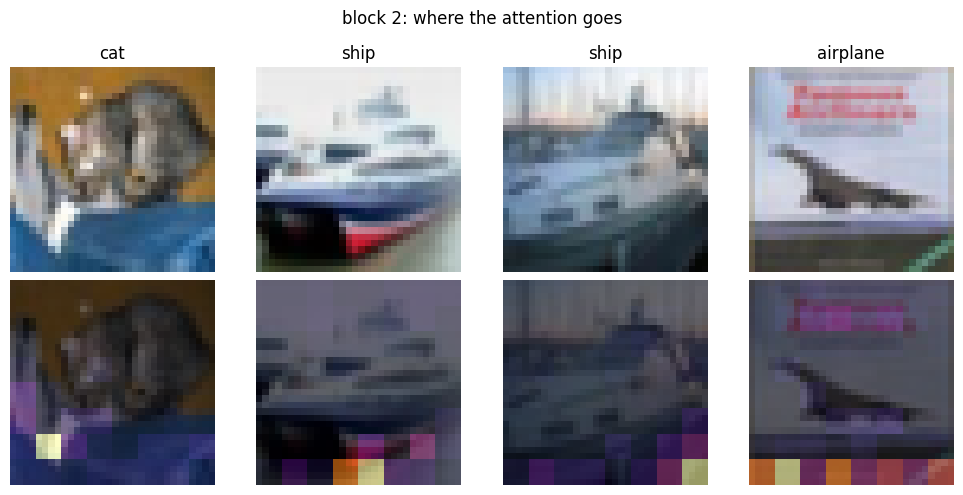

In [16]:
def attention_scores(model, block, images):
    """Attention weights of one block: (n, heads, 64 looking, 64 looked at)."""
    to_block = keras.Model(model.input, model.get_layer(f"block{block}_norm1").output)
    h = to_block.predict(images, batch_size=250, verbose=0)              # what the attention layer receives
    _, scores = model.get_layer(f"block{block}_attention")(h, h, return_attention_scores=True)
    return scores.numpy()


euclid = np.sqrt((rows[:, None] - rows[None, :]) ** 2 + (cols[:, None] - cols[None, :]) ** 2)
print(f"mean distance if attention were spread evenly: {euclid.mean():.2f} patches")
att = {}
for b in (1, 2):
    att[b] = attention_scores(vit, b, x_test[:500])
    assert np.allclose(att[b].sum(-1), 1, atol=1e-4)
    per_head = (att[b] * euclid).sum(-1).mean(axis=(0, 2))
    print(f"block {b}: mean attention distance {per_head.mean():.2f} patches   per head: {per_head}")
    print(f"         largest single weight, on average: {att[b].max(-1).mean():.3f}   (even spread = {1 / 64:.3f})")

received = att[2].mean(axis=(1, 2)).reshape(-1, 8, 8)                    # (500, 8, 8)
print("attention received by each patch in block 2, for test image 0, as multiples of an even share:")
print(received[0] * 64)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k in range(4):
    axes[0, k].imshow(x_test[k]); axes[0, k].axis("off")
    axes[0, k].set_title(CLASSES[y_test[k]])
    axes[1, k].imshow(x_test[k])
    axes[1, k].imshow(np.kron(received[k], np.ones((4, 4))), cmap="inferno", alpha=0.6); axes[1, k].axis("off")
plt.suptitle("block 2: where the attention goes"); plt.tight_layout(); plt.show()

### Why we see this

A convolution's first layer can only look 1 pixel to each side. Attention has no such limit, and this tiny
model uses none: in both blocks the mean distance is close to the 4.14 patches of an even spread, which is
about 16 pixels, half the width of the picture. The weights are not even (the largest is about nine times an
even share), but what they pick out is spread across the whole image, not gathered round the patch that is
looking. In the published analysis of large ViTs the lowest layers contain both local and global heads, and
the upper layers are mostly global. A global view from the first layer is what a ViT has that a CNN lacks,
and locality is what a CNN has that a ViT must learn. Ours, after 600 steps, has not learnt it.

The map shows **where the weights are large**. It does not show why the model gave its answer. Attention
weights are one step in a computation that also has value vectors, residual paths and two feed-forward
layers; a patch with a large weight may contribute little, and a block may attend to the background to find
out that it is background. Treat an attention map as a clue about routing. Chapter 62 covers the tools that
test whether a region actually changed the answer.

---
## Step 17 - What a smaller patch costs

A smaller patch means finer detail and more tokens. Attention compares every token with every token, so its
table of scores has (number of tokens)² cells, per head, per block.

> **Predict:** halve the patch size. By what factor do the tokens grow? And the attention table?

In [17]:
print(f"{'image':>6s} {'patch':>6s} {'tokens':>8s} {'cells in one attention table':>30s} {'vs row above':>13s}")
for image, patches in [(32, (8, 4, 2)), (224, (32, 16, 8)), (384, (16,))]:
    previous = None
    for p in patches:
        n = (image // p) ** 2
        ratio = "" if previous is None else f"{n * n / previous:.0f} x"
        print(f"{image:6d} {p:6d} {n:8,d} {n * n:30,d} {ratio:>13s}")
        previous = n * n
    print()
print("224 x 224 at patch 16:", (224 // 16) ** 2, "patches + 1 class token =", (224 // 16) ** 2 + 1, "tokens")
print("384 x 384 at patch 16:", (384 // 16) ** 2, "patches:",
      f"{(384 // 16) ** 2 / (224 // 16) ** 2:.2f} x the tokens, {((384 // 16) ** 2 / (224 // 16) ** 2) ** 2:.1f} x the attention table")

 image  patch   tokens   cells in one attention table  vs row above
    32      8       16                            256              
    32      4       64                          4,096          16 x
    32      2      256                         65,536          16 x

   224     32       49                          2,401              
   224     16      196                         38,416          16 x
   224      8      784                        614,656          16 x

   384     16      576                        331,776              

224 x 224 at patch 16: 196 patches + 1 class token = 197 tokens
384 x 384 at patch 16: 576 patches: 2.94 x the tokens, 8.6 x the attention table


### Why we see this

Halving the patch size makes four times as many tokens and an attention table sixteen times as large. The
feed-forward layers and the rest of the model grow by four (they work token by token); attention grows by
sixteen. That is why ViT-Base uses 16 × 16 patches on a 224 × 224 image and not 4 × 4, why our lab can afford
4 × 4 only because the image is 32 × 32, and why high-resolution images are expensive for a plain ViT.
Chapter 25 is about ways round the quadratic cost; in vision the common ones are windows (Swin, 2021) and
pooling tokens as the model gets deeper.

---
## Step 18 - TinyViT beside ViT-Base/16

ViT-Base/16 (2020) is the same design with bigger numbers: 224 × 224 images, 16 × 16 patches, width 768, 12
blocks, 12 heads, feed-forward 3,072, a class token, and a head for the 1,000 classes of ImageNet.

> **Predict:** its token count, its patch-projection count, and which GPT-2 number its block equals.

In [18]:
base_parts, base_block = count_vit(image=224, patch=16, d=768, blocks=12, ff=3072, classes=1000, class_token=True)
print(f"{'':17s} {'TinyViT':>10s} {'ViT-Base/16':>14s}")
for name in base_parts:
    print(f"{name:17s} {vit_parts[name]:>10,} {base_parts[name]:>14,}")
BASE_TOTAL = sum(base_parts.values())
print(f"{'TOTAL':17s} {VIT_HAND:>10,} {BASE_TOTAL:>14,}")
assert base_parts["patch projection"] == 590_592 and base_block == 7_087_872 and BASE_TOTAL == 86_567_656
print(f"one ViT-Base block: {base_block:,} (the same as one GPT-2 small block)")
print(f"ViT-Base/16 is {BASE_TOTAL / VIT_HAND:,.0f} times TinyViT; its blocks hold {base_parts['blocks'] / BASE_TOTAL:.1%} of it")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

                     TinyViT    ViT-Base/16
patch projection       3,136        590,592
class token                0            768
position table         4,096        151,296
blocks                99,968     85,054,464
final norm               128          1,536
head                     650        769,000
TOTAL                107,978     86,567,656
one ViT-Base block: 7,087,872 (the same as one GPT-2 small block)
ViT-Base/16 is 802 times TinyViT; its blocks hold 98.3% of it

whole notebook: 249 s


### Why we see this

196 patches and a class token make 197 tokens. The projection is 16 · 16 · 3 · 768 + 768 = 590,592, and the
block is 7,087,872, to the last digit the block of GPT-2 small (Chapter 35): same width, same feed-forward
size, same formula. A ViT is a language-model body with a different front door.

What does not scale from this notebook is the training. The original ViT results that beat CNNs came from
pretraining on hundreds of millions of labelled images; trained on ImageNet's 1.3 million alone with the
recipe of the time, the same models were behind comparable CNNs. That gap is the one you measured in Step 12.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 6: `build_vit(patch=8)` (16 tokens of 192 numbers) | Parameter count? Faster or slower per step? Better or worse? | |
| 2 | Step 6: `build_vit(patch=2)` (256 tokens); train on the tenth set only | How much slower is a step: 4 times or 16 times? | |
| 3 | Step 11: train both models on `x_all[:3000]` | Where does the gap between CNN and ViT fall between the two you measured? | |
| 4 | Step 10: `STEPS = 1800` for both | Which model gains more from three times the training? | |
| 5 | Step 10: swap the two peak learning rates | Which model minds more? | |
| 6 | Step 6: `build_vit(pool="cls")` | 108,106 parameters. Does the class token beat the mean at this size? | |
| 7 | Step 14: scramble with `p=16` (four big tiles) | Which models survive a coarse scramble better than a fine one? | |
| 8 | Steps 6 and 8: remove the `RandomFlip` from the ViT only | How unfair does the comparison become on the tenth set? | |

---
## Exercises

1. **Interpolate the positions.** Take the trained 64 × 64 position table, reshape it to (8, 8, 64), and
   resize it to (16, 16, 64) with `keras.ops.image.resize` (bilinear). Build `build_vit(image=64)`, copy every
   trained weight across and put the resized table in. Evaluate on test images enlarged to 64 × 64. Then try
   it with a randomly initialised table instead of the interpolated one.
2. **A hybrid.** Replace the patch projection with two 3 × 3 convolutions of stride 2 (a "conv stem") that
   also end at an 8 × 8 grid of 64 channels. Hand-count the new total first. Does it help on the tenth set?
3. **Sinusoidal positions.** Use the fixed table of Chapter 34 for the 64 positions instead of a learnt one.
   What does the Step 15 map look like before any training?
4. **Seeds.** Run the two all-label runs with three different seeds each. How large is the spread within a
   model compared with the gap between the models?
5. **Translation.** Roll every test image 4 pixels to the right with `np.roll`. Compare the drop in accuracy
   for the CNN and the ViT, then repeat with a roll of 2 pixels. Why might 2 hurt the ViT more than 4?
6. **Attention distance by head.** Plot the Step 16 distance for each of the eight heads, before training and
   after. Which heads became local?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Patchify | H × W × C image, P × P patches → (H/P)·(W/P) tokens of P·P·C numbers; P must divide H and W |
| Patch projection | `Conv2D(d, kernel_size=P, strides=P)`: P·P·C·d + d parameters |
| TinyViT | 32 × 32 image, P = 4, 64 tokens, d = 64, 4 heads, 2 blocks, ff = 256: 107,978 parameters |
| Shapes | (B, 32, 32, 3) → (B, 8, 8, 64) → (B, 64, 64) through every block → (B, 64) → (B, 10) |
| The block | Chapter 23's encoder block: TinyGPT's block without the causal mask (49,984 at d = 64) |
| Positions | a learnt table, one row per token; without it the model sees a bag of patches |
| Readout | mean of the tokens, or a class token (+ d for the token, + d for its position row) |
| Jigsaw test | scramble the patches: a model with working positions must get worse |
| Inductive bias | CNN: locality and translation equivariance built in. ViT: learns them from data |
| Small data | the CNN wins; the ViT memorises. More data closes the gap |
| Cost | halve P: 4 × the tokens, 16 × the attention table |
| Fair comparison | same data, same steps, same augmentation; tune each model's learning rate on held-out training data |
| ViT-Base/16 (2020) | 197 tokens, projection 590,592, block 7,087,872, total 86,567,656 with a 1,000-class head |